In [207]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

In [208]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\massive_employee_practice_dataset.csv")

In [209]:
df.shape

(10120, 20)

In [210]:
df.columns

Index(['Employee_ID', 'Full_Name', 'Age', 'Gender', 'Department', 'Job_Title',
       'City', 'Education', 'Salary', 'Bonus', 'Joining_Date',
       'Experience_Years', 'Performance_Rating', 'Projects_Completed',
       'Remote_Work', 'Employment_Status', 'Email', 'Overtime_Hours',
       'Monthly_Sales', 'Last_Review_Date'],
      dtype='object')

In [211]:
df.head()

,Employee_ID,Full_Name,Age,Gender,Department,Job_Title,City,Education,Salary,Bonus,Joining_Date,Experience_Years,Performance_Rating,Projects_Completed,Remote_Work,Employment_Status,Email,Overtime_Hours,Monthly_Sales,Last_Review_Date
0,EMP13360,Ananya Patil,45.0,Male,HR,Developer,Pune,Master's,68660.0,8601.0,12-11-2019,13.1,2,17,Hybrid,Resigned,employee3360@example.com,30.9,13306.58,2025-04-02
1,EMP19369,Ananya Patil,34.0,FEMALE,FINANCE,Developer,Delhi,Bachelor's,15629.0,699.0,07-22-2022,18.8,NaN,0,Yes,INACTIVE,employee9369@example.com,33.3,30004.81,2025-03-10
2,EMP16895,Sneha Deshmukh,38.0,F,it,Team Lead,Bengaluru,bachelor's,40849.0,3401.0,2024-04-08,2.7,3,5,Yes,Resigned,employee6895@example.com,13.4,NaN,2026-06-04
3,EMP15214,Vikram Patil,31.0,Female,FINANCE,Team Lead,Mumbai,High School,37201.0,819.0,12/08/2023,11.1,4,30,No,Active,employee5214@example.com,20.9,NaN,2026-10-05
4,EMP17380,Ananya Kulkarni,25.0,F,Support,Support Engineer,Nagpur,Diploma,51566.0,1997.0,07/10/2025,14.7,1,29,Yes,On Leave,employee7380@example.com,33.2,224435.73,2026-06-29


In [212]:
df.tail()

,Employee_ID,Full_Name,Age,Gender,Department,Job_Title,City,Education,Salary,Bonus,Joining_Date,Experience_Years,Performance_Rating,Projects_Completed,Remote_Work,Employment_Status,Email,Overtime_Hours,Monthly_Sales,Last_Review_Date
10115,EMP17891,Vikram Kulkarni,28.0,NaN,FINANCE,Intern,pune,Bachelor's,44946.0,4892.0,08-27-2020,23.1,3,8,no,Resigned,employee7891@example.com,19.9,210149.96,2025-02-07
10116,EMP11769,Karan Khan,37.0,Female,Finance,Analyst,Bengaluru,Master's,32351.0,681.0,04-05-2021,11.2,1,35,YES,Inactive,employee1769@example.com,21.8,168354.49,2026-03-24
10117,EMP19930,Rohan Sharma,19.0,Female,it,Developer,Bengaluru,PhD,40561.0,6836.0,13/08/2020,20.4,3,23,Hybrid,Resigned,employee9930@example.com,12.8,16870.06,2025-11-28
10118,EMP13241,Priya Sharma,37.0,F,HR,Intern,Bengaluru,Masters,18723.0,1981.0,05/01/2023,20.2,NaN,6,Yes,active,employee3241@example.com,7.7,98041.70,2025-11-28
10119,EMP17204,Rohan Deshmukh,34.0,F,it,Accountant,Nashik,Masters,26205.0,4572.0,04/02/2026,24.2,1,31,no,On Leave,employee7204@example.com,24.5,NaN,2026-05-20


In [213]:
df["Education"].value_counts()

Education
Master's       1435
High School    1405
Masters        1397
Diploma        1394
bachelor's     1380
Bachelor's     1368
PhD            1341
Name: count, dtype: int64

In [214]:
df["Education"] = df["Education"].str.capitalize()

In [215]:
df["Full_Name"].apply(lambda x:x.split()[0::-1]).head()

0    [Ananya]
1    [Ananya]
2     [Sneha]
3    [Vikram]
4    [Ananya]
Name: Full_Name, dtype: object

In [216]:
df.duplicated().sum()

np.int64(120)

In [217]:
df.drop_duplicates(inplace=True)

In [218]:
df.shape

(10000, 20)

In [219]:
df.isna().sum()

Employee_ID              0
Full_Name                0
Age                    237
Gender                 386
Department             323
Job_Title                0
City                   336
Education              394
Salary                 228
Bonus                  392
Joining_Date           255
Experience_Years         0
Performance_Rating    1712
Projects_Completed       0
Remote_Work              0
Employment_Status        0
Email                  175
Overtime_Hours           0
Monthly_Sales         4525
Last_Review_Date         0
dtype: int64

In [220]:
df["Age"] = pd.to_numeric(df["Age"],errors="raise")

ValueError: Unable to parse string "34 years" at position 24

In [221]:
df["Age"] = df["Age"].astype("Int64")

ValueError: invalid literal for int() with base 10: '45.0'

In [222]:
df.loc[24]

Employee_ID                           EMP14323
Full_Name                         Ananya Joshi
Age                                   34 years
Gender                                    Male
Department                                  HR
Job_Title                              Manager
City                                    Nagpur
Education                           Bachelor's
Salary                                 19213.0
Bonus                                    920.0
Joining_Date                        2022-05-06
Experience_Years                          15.0
Performance_Rating                           1
Projects_Completed                          27
Remote_Work                             Hybrid
Employment_Status                       Active
Email                 employee4323@example.com
Overtime_Hours                            10.0
Monthly_Sales                              NaN
Last_Review_Date                    2025-05-03
Name: 24, dtype: object

In [223]:
df["Age"] = df["Age"].str.replace(" years", "", regex=False)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

In [224]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 10119
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         10000 non-null  object 
 1   Full_Name           10000 non-null  object 
 2   Age                 9763 non-null   float64
 3   Gender              9614 non-null   object 
 4   Department          9677 non-null   object 
 5   Job_Title           10000 non-null  object 
 6   City                9664 non-null   object 
 7   Education           9606 non-null   object 
 8   Salary              9772 non-null   object 
 9   Bonus               9608 non-null   float64
 10  Joining_Date        9745 non-null   object 
 11  Experience_Years    10000 non-null  float64
 12  Performance_Rating  8288 non-null   object 
 13  Projects_Completed  10000 non-null  int64  
 14  Remote_Work         10000 non-null  object 
 15  Employment_Status   10000 non-null  object 
 16  Email    

In [225]:
df["Age"] = df["Age"].fillna(df["Age"].mean())

In [226]:
df.isna().sum()

Employee_ID              0
Full_Name                0
Age                      0
Gender                 386
Department             323
Job_Title                0
City                   336
Education              394
Salary                 228
Bonus                  392
Joining_Date           255
Experience_Years         0
Performance_Rating    1712
Projects_Completed       0
Remote_Work              0
Employment_Status        0
Email                  175
Overtime_Hours           0
Monthly_Sales         4525
Last_Review_Date         0
dtype: int64

In [227]:
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])

In [228]:
df["Gender"].value_counts()

Gender
Other     1805
Female    1414
Male      1371
male      1368
F         1366
M         1361
FEMALE    1315
Name: count, dtype: int64

In [229]:
df.loc[df["Gender"]=="M","Gender"]="Male"
df.loc[df["Gender"]=="F","Gender"]="Female"
df.loc["Gender"] = df["Gender"].str.lower()

In [230]:
df["Gender"].value_counts()

Gender
Female    2780
Male      2732
Other     1805
male      1368
FEMALE    1315
Name: count, dtype: int64

In [231]:
df.loc[df["Gender"]=="FEMALE","Gender"]="Female"

In [232]:
df["Gender"] = df["Gender"].str.capitalize()

In [233]:
df["Gender"].value_counts()

Gender
Male      4100
Female    4095
Other     1805
Name: count, dtype: int64

In [234]:
df["Age"] = pd.to_numeric(df["Age"])

In [235]:
df["Age"] = df["Age"].astype("int64")

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer

In [236]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10001 entries, 0 to Gender
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         10000 non-null  object 
 1   Full_Name           10000 non-null  object 
 2   Age                 10000 non-null  float64
 3   Gender              10000 non-null  object 
 4   Department          9677 non-null   object 
 5   Job_Title           10000 non-null  object 
 6   City                9664 non-null   object 
 7   Education           9606 non-null   object 
 8   Salary              9772 non-null   object 
 9   Bonus               9608 non-null   float64
 10  Joining_Date        9745 non-null   object 
 11  Experience_Years    10000 non-null  float64
 12  Performance_Rating  8288 non-null   object 
 13  Projects_Completed  10000 non-null  float64
 14  Remote_Work         10000 non-null  object 
 15  Employment_Status   10000 non-null  object 
 16  Email   

In [237]:
# df[df["Department"].isna()]\
df["Department"].value_counts()

Department
IT            1064
FINANCE       1033
Marketing      992
HR             974
Finance        962
HR             955
it             942
Sales          895
Support        893
Operations     869
MARKETING       31
SUPPORT         24
SALES           24
OPERATIONS      19
Name: count, dtype: int64

In [238]:
df["Department"] = df["Department"].fillna(df["Department"].mode()[0])

In [239]:

df.loc[14]

Employee_ID                           EMP11430
Full_Name                          Isha Sharma
Age                                       41.0
Gender                                   Other
Department                                  IT
Job_Title                            Executive
City                                     Dhule
Education                           Bachelor's
Salary                                 50886.0
Bonus                                   3075.0
Joining_Date                        25/07/2020
Experience_Years                           6.9
Performance_Rating                           2
Projects_Completed                        23.0
Remote_Work                                 no
Employment_Status                     On Leave
Email                 employee1430@example.com
Overtime_Hours                            23.2
Monthly_Sales                         89399.53
Last_Review_Date                    2025-04-28
Name: 14, dtype: object

In [240]:
df["Department"].value_counts()

Department
IT            1388
FINANCE       1033
Marketing      992
HR             974
Finance        962
HR             955
it             942
Sales          895
Support        893
Operations     869
MARKETING       31
SUPPORT         24
SALES           24
OPERATIONS      19
Name: count, dtype: int64

In [241]:
df["Department"] = df["Department"].str.lower()

In [242]:
df["Department"].value_counts()

df["Department"] = df["Department"].str.capitalize()

In [243]:
df["Department"].value_counts()

Department
It            2330
Finance       1995
Marketing     1023
Hr             974
Hr             955
Sales          919
Support        917
Operations     888
Name: count, dtype: int64

In [244]:
df["Department"] = df["Department"].str.strip()

In [245]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                1
City                   337
Education              395
Salary                 229
Bonus                  393
Joining_Date           256
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [246]:
df["City"] = df["City"].fillna(df["City"].mode()[0])

In [247]:
df["Education"].value_counts()

Education
Bachelor's     2727
Master's       1415
High school    1385
Masters        1380
Diploma        1374
Phd            1325
Name: count, dtype: int64

In [248]:
df["Education"] = df["Education"].fillna(df["Education"].mode()) 

In [249]:
df["Salary"] = pd.to_numeric(df["Salary"])

ValueError: Unable to parse string "₹43,419" at position 83

In [250]:
df["Salary"] = df["Salary"].str.replace("₹", "", regex=False)

df["Salary"] = df["Salary"].str.replace(",", "", regex=False)

df["Salary"] = pd.to_numeric(df["Salary"], errors="coerce")

In [251]:
df["Salary"] = df["Salary"].fillna(df["Salary"].mean())

In [252]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                1
City                     0
Education              395
Salary                   0
Bonus                  393
Joining_Date           256
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [253]:
df["Education"] = df["Education"].fillna(df["Education"].mode()[0])

In [254]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                1
City                     0
Education                0
Salary                   0
Bonus                  393
Joining_Date           256
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [255]:
df["Joining_Date"] = pd.to_datetime(df["Joining_Date"],format="mixed")

DateParseError: Unknown datetime string format, unable to parse: not available, at position 17

In [256]:
import numpy as np
df["Joining_Date"]=df["Joining_Date"].replace("not available",np.nan)

In [257]:
df["Joining_Date"].isna().sum()

np.int64(451)

In [258]:
df["Joining_Date"] = pd.to_datetime(df["Joining_Date"],format="mixed")

In [259]:
df["Joining_Date"] = df["Joining_Date"].fillna(df["Joining_Date"].mode()[0]) 

In [260]:
df["Bonus"] = df["Bonus"].astype("Int64")

In [261]:
df["Bonus"] = df["Bonus"].fillna(round(df["Bonus"].mean()))

In [262]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                1
City                     0
Education                0
Salary                   0
Bonus                    0
Joining_Date             0
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [263]:
df["Job_Title"] = df["Job_Title"].fillna(df["Job_Title"].mode()[0])

In [264]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                0
City                     0
Education                0
Salary                   0
Bonus                    0
Joining_Date             0
Experience_Years         1
Performance_Rating    1713
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [265]:
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].mean())

TypeError: can only concatenate str (not "int") to str

In [266]:
df["Performance_Rating"] = pd.to_numeric(df["Performance_Rating"],errors="coerce")

In [267]:
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].mean())

In [268]:
df.isna().sum()

Employee_ID              1
Full_Name                1
Age                      1
Gender                   1
Department               0
Job_Title                0
City                     0
Education                0
Salary                   0
Bonus                    0
Joining_Date             0
Experience_Years         1
Performance_Rating       0
Projects_Completed       1
Remote_Work              1
Employment_Status        1
Email                  176
Overtime_Hours           1
Monthly_Sales         4526
Last_Review_Date         1
dtype: int64

In [269]:
df["Monthly_Sales"] = df["Monthly_Sales"].astype("Int64")

TypeError: cannot safely cast non-equivalent object to int64

In [ ]:
print(df["Monthly_Sales"].unique())
print(df["Monthly_Sales"].dtype)

In [ ]:
df["Monthly_Sales"] = pd.to_numeric(
    df["Monthly_Sales"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

In [ ]:
df["Monthly_Sales"] = df["Monthly_Sales"].astype("Int64")

In [ ]:
df["Monthly_Sales"] = df["Monthly_Sales"].fillna(df["Monthly_Sales"].mean())

In [ ]:
df.isna().sum()

In [270]:
df.dropna(inplace=True)

In [271]:
df.isna().sum()

Employee_ID           0
Full_Name             0
Age                   0
Gender                0
Department            0
Job_Title             0
City                  0
Education             0
Salary                0
Bonus                 0
Joining_Date          0
Experience_Years      0
Performance_Rating    0
Projects_Completed    0
Remote_Work           0
Employment_Status     0
Email                 0
Overtime_Hours        0
Monthly_Sales         0
Last_Review_Date      0
dtype: int64

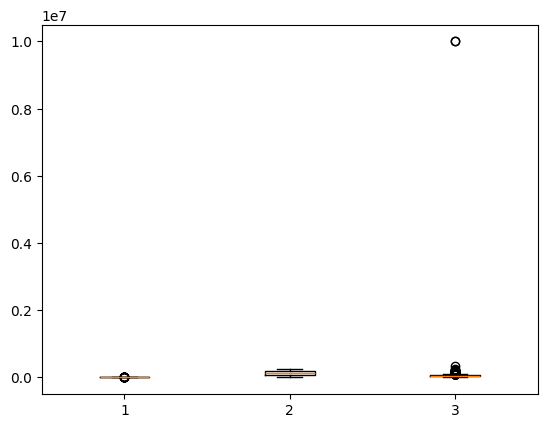

In [272]:
plt.boxplot(df[["Age","Monthly_Sales","Salary"]])
plt.show()

In [273]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)

IQR = Q3-Q1

lower = Q1-1.5*(IQR)
HIGER = Q3+1.5*(IQR)

a = df[(df["Age"]<lower) | (df["Age"]>HIGER)].index

In [274]:
df.drop(a,inplace=True)


In [275]:
df.shape

(5360, 20)

In [276]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [277]:
q1 = df["Monthly_Sales"].quantile(0.25)
q3 = df["Monthly_Sales"].quantile(0.75)

iqr = q3-q1

low = q1-1.5*(iqr)
high = q3+1.5*(iqr)

df[(df["Monthly_Sales"]<low) | (df["Monthly_Sales"]>high)]

,Employee_ID,Full_Name,Age,Gender,Department,Job_Title,City,Education,Salary,Bonus,Joining_Date,Experience_Years,Performance_Rating,Projects_Completed,Remote_Work,Employment_Status,Email,Overtime_Hours,Monthly_Sales,Last_Review_Date


In [278]:
df.shape

(5360, 20)

In [279]:
num_cols = df.select_dtypes(include="number").columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, ":", count)

Age : 0
Salary : 201
Bonus : 201
Experience_Years : 5
Performance_Rating : 610
Projects_Completed : 0
Overtime_Hours : 0
Monthly_Sales : 0


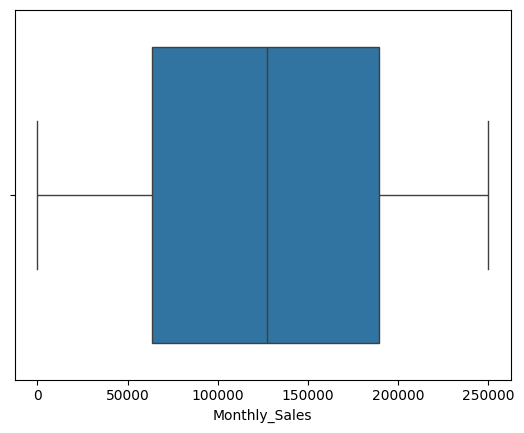

In [280]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df["Monthly_Sales"])
plt.show()

In [281]:
df.isna().sum()

Employee_ID           0
Full_Name             0
Age                   0
Gender                0
Department            0
Job_Title             0
City                  0
Education             0
Salary                0
Bonus                 0
Joining_Date          0
Experience_Years      0
Performance_Rating    0
Projects_Completed    0
Remote_Work           0
Employment_Status     0
Email                 0
Overtime_Hours        0
Monthly_Sales         0
Last_Review_Date      0
dtype: int64

In [282]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [283]:
df

,Employee_ID,Full_Name,Age,Gender,Department,Job_Title,City,Education,Salary,Bonus,Joining_Date,Experience_Years,Performance_Rating,Projects_Completed,Remote_Work,Employment_Status,Email,Overtime_Hours,Monthly_Sales,Last_Review_Date
0,EMP13360,Ananya Patil,45.0,Male,Hr,Developer,Pune,Master's,68660.0,8601,2019-12-11,13.1,2.000000,17.0,Hybrid,Resigned,employee3360@example.com,30.9,13306.58,2025-04-02
1,EMP19369,Ananya Patil,34.0,Female,Finance,Developer,Delhi,Bachelor's,15629.0,699,2022-07-22,18.8,3.142909,0.0,Yes,INACTIVE,employee9369@example.com,33.3,30004.81,2025-03-10
4,EMP17380,Ananya Kulkarni,25.0,Female,Support,Support Engineer,Nagpur,Diploma,51566.0,1997,2025-07-10,14.7,1.000000,29.0,Yes,On Leave,employee7380@example.com,33.2,224435.73,2026-06-29
6,EMP15832,Neha Sharma,44.0,Male,Marketing,Developer,Aurangabad,Bachelor's,35143.0,759,2022-09-23,22.6,3.000000,9.0,Yes,active,employee5832@example.com,37.2,149007.95,2025-08-17
8,EMP18377,Ananya Pawar,27.0,Female,Hr,Support Engineer,Delhi,Bachelor's,35293.0,2125,2020-05-10,13.2,2.000000,28.0,Hybrid,active,employee8377@example.com,26.4,82245.64,2025-04-22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10113,EMP17366,Ananya Kulkarni,19.0,Male,Sales,Executive,MUMBAI,Bachelor's,41865.0,1559,2020-01-26,10.5,5.000000,21.0,Hybrid,INACTIVE,employee7366@example.com,29.5,97024.92,2026-01-12
10115,EMP17891,Vikram Kulkarni,28.0,Other,Finance,Intern,pune,Bachelor's,44946.0,4892,2020-08-27,23.1,3.000000,8.0,no,Resigned,employee7891@example.com,19.9,210149.96,2025-02-07
10116,EMP11769,Karan Khan,37.0,Female,Finance,Analyst,Bengaluru,Master's,32351.0,681,2021-04-05,11.2,1.000000,35.0,YES,Inactive,employee1769@example.com,21.8,168354.49,2026-03-24
10117,EMP19930,Rohan Sharma,19.0,Female,It,Developer,Bengaluru,Phd,40561.0,6836,2020-08-13,20.4,3.000000,23.0,Hybrid,Resigned,employee9930@example.com,12.8,16870.06,2025-11-28


In [284]:
model = LinearRegression()
model2 = DecisionTreeClassifier()
le = LabelEncoder()

In [285]:
df.columns

Index(['Employee_ID', 'Full_Name', 'Age', 'Gender', 'Department', 'Job_Title',
       'City', 'Education', 'Salary', 'Bonus', 'Joining_Date',
       'Experience_Years', 'Performance_Rating', 'Projects_Completed',
       'Remote_Work', 'Employment_Status', 'Email', 'Overtime_Hours',
       'Monthly_Sales', 'Last_Review_Date'],
      dtype='object')

In [286]:
df['Gender'] = le.fit_transform(df['Gender'])
df['Job_Title'] = le.fit_transform(df['Job_Title'])
df['City'] = le.fit_transform(df['City'])

In [287]:
x = df[["Age","Gender","Job_Title","City","Salary","Experience_Years","Performance_Rating"]]
y = df["Monthly_Sales"] 

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=333)

In [288]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [289]:
x_test

,Age,Gender,Job_Title,City,Salary,Experience_Years,Performance_Rating
3704,27.0,2,5,9,56813.759415,5.0,2.0
4521,22.0,1,0,2,29175.000000,4.8,4.0
8688,38.0,2,4,7,35483.000000,11.7,3.0
5880,26.0,0,0,6,25576.000000,22.6,5.0
1479,21.0,1,0,2,85455.000000,3.8,4.0
...,...,...,...,...,...,...,...
1126,36.0,2,1,8,30034.000000,0.2,4.0
2264,38.0,0,7,7,15964.000000,1.1,2.0
2317,27.0,1,1,9,28282.000000,14.5,1.0
9757,19.0,1,0,6,36712.000000,14.2,3.0


In [290]:
y_test

3704    175161.74
4521     29832.55
8688    158453.99
5880    207760.97
1479     69139.14
          ...    
1126    146342.55
2264    145275.22
2317    131254.42
9757    214756.80
3993    204627.85
Name: Monthly_Sales, Length: 1072, dtype: float64

In [291]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [292]:
y_predict = model.predict(x_test)

In [293]:
y_predict

array([129270.47062805, 129224.58595943, 130612.78835176, ...,
       128575.54791199, 128630.3471314 , 131607.59309945], shape=(1072,))

In [294]:
y_test

3704    175161.74
4521     29832.55
8688    158453.99
5880    207760.97
1479     69139.14
          ...    
1126    146342.55
2264    145275.22
2317    131254.42
9757    214756.80
3993    204627.85
Name: Monthly_Sales, Length: 1072, dtype: float64

In [295]:
mae = mean_absolute_error(y_test,y_predict)

In [296]:
mae

62383.44808025266

In [297]:
mse = mean_squared_error(y_test,y_predict)

In [298]:
mse

5153251529.160094

In [299]:
rmse = root_mean_squared_error(y_test,y_predict)

In [300]:
rmse

71786.15137448235

In [301]:
r2 = r2_score(y_test,y_predict)

In [302]:
r2

0.0002823332986803262

In [303]:
x

,Age,Gender,Job_Title,City,Salary,Experience_Years,Performance_Rating
0,45.0,1,2,8,68660.0,13.1,2.000000
1,34.0,0,2,3,15629.0,18.8,3.142909
4,25.0,0,6,6,51566.0,14.7,1.000000
6,44.0,1,2,1,35143.0,22.6,3.000000
8,27.0,0,6,3,35293.0,13.2,2.000000
...,...,...,...,...,...,...,...
10113,19.0,1,3,0,41865.0,10.5,5.000000
10115,28.0,2,4,9,44946.0,23.1,3.000000
10116,37.0,0,1,2,32351.0,11.2,1.000000
10117,19.0,0,2,2,40561.0,20.4,3.000000


In [304]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [305]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\massive_employee_salary_cleaning_dataset.csv")

In [306]:
df.head()

,Employee_ID,Age,Experience_Years,Education,Department,City,Performance_Rating,Projects_Completed,Training_Hours,Weekly_Working_Hours,Company_Size,Annual_Salary
0,EMP00001,24.0,1.0,Master,Operations,Pune,1.7,5.0,6.0,38.1,Medium,85131.0
1,EMP00002,51.0,29.0,Masters,Marketing,Hyderabad,2.5,12.0,3.0,30.6,Large,183609.0
2,EMP00003,47.0,22.0,Bachelor,Sales,Nagpur,2.4,3.0,2.0,31.0,Large,"125,571"
3,EMP00004,38.0,11.0,High School,Operations,Hyderabad,2.7,5.0,2.0,35.4,NaN,87186.0
4,EMP00005,38.0,16.0,Bachelor,Operations,Nashik,3.4,9.0,NaN,31.6,Small,114793.0


In [307]:
df.tail()

,Employee_ID,Age,Experience_Years,Education,Department,City,Performance_Rating,Projects_Completed,Training_Hours,Weekly_Working_Hours,Company_Size,Annual_Salary
10075,EMP04432,24.0,4.0,Master,Finance,Nashik,3.5,NaN,1.0,25.2,Large,116391.0
10076,EMP06401,42.0,19.0,Master,Finance,Delhi,NaN,4.0,3.0,43.3,Small,148528.0
10077,EMP02905,47.0,17.0,High School,Operations,Mumbai,2.7,5.0,2.0,45.2,Medium,131685.0
10078,EMP03060,31.0,11.0,Bachelor,Finance,Nashik,3.4,3.0,3.0,37.8,Large,103817.0
10079,EMP08359,48.0,25.0,High School,HR,Nashik,3.6,9.0,0.0,56.1,Medium,138939.0


In [308]:
df.duplicated().sum()

np.int64(80)

In [309]:
df.drop_duplicates(inplace=True)

In [310]:
df.isna().sum()

Employee_ID               0
Age                     249
Experience_Years        350
Education               200
Department              250
City                    200
Performance_Rating      400
Projects_Completed      250
Training_Hours          300
Weekly_Working_Hours    250
Company_Size            200
Annual_Salary           150
dtype: int64

In [311]:
# df["Age"] = df["Age"].astype("int")

df["Age"] = pd.to_numeric(df["Age"])

In [312]:
df["Age"] = df["Age"].astype("Int64")

In [313]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Employee_ID           10000 non-null  object 
 1   Age                   9751 non-null   Int64  
 2   Experience_Years      9650 non-null   float64
 3   Education             9800 non-null   object 
 4   Department            9750 non-null   object 
 5   City                  9800 non-null   object 
 6   Performance_Rating    9600 non-null   float64
 7   Projects_Completed    9750 non-null   float64
 8   Training_Hours        9700 non-null   float64
 9   Weekly_Working_Hours  9750 non-null   float64
 10  Company_Size          9800 non-null   object 
 11  Annual_Salary         9850 non-null   object 
dtypes: Int64(1), float64(5), object(6)
memory usage: 1.0+ MB


In [314]:
df.describe()

,Age,Experience_Years,Performance_Rating,Projects_Completed,Training_Hours,Weekly_Working_Hours
count,9751.0,9650.000000,9600.00000,9750.000000,9700.000000,9750.000000
mean,40.461799,15.824663,3.19475,5.001538,2.991959,42.038318
std,11.71716,11.426512,0.79579,2.260431,1.718676,7.453050
min,21.0,0.000000,1.00000,0.000000,0.000000,20.000000
25%,30.0,5.000000,2.70000,3.000000,2.000000,37.100000
50%,40.0,15.000000,3.20000,5.000000,3.000000,41.900000
75%,50.0,25.000000,3.70000,6.000000,4.000000,46.800000
max,121.0,64.000000,5.00000,14.000000,12.000000,128.000000


In [315]:
df.describe(include="object")

,Employee_ID,Education,Department,City,Company_Size,Annual_Salary
count,10000,9800,9750,9800,9800,9850
unique,10000,6,9,9,3,9506
top,EMP09984,Bachelor,Marketing,Nashik,Medium,152957.0
freq,1,4513,1652,1453,4382,3


In [316]:
df["Education"].value_counts()

Education
Bachelor       4513
Master         2702
High School    1747
PhD             585
bachelor        160
Masters          93
Name: count, dtype: int64

In [317]:
df["Age"] = df["Age"].fillna(round(df["Age"].mean()))

In [318]:
df["Education"] = df["Education"].str.strip()

df["Education"] = df["Education"].str.capitalize()

df["Education"].value_counts()

df.loc[df["Education"]=="Master","Education"]="Masters"

df["Education"].value_counts()

# df["Education"]= df["Education"].fillna(df["Education"].mode()[0])

df["Education"].isna().sum()

np.int64(200)

In [319]:
df.drop(columns="Employee_ID",inplace=True)

In [320]:
# df["Experience_Years"] = df["Experience_Years"].astype("int64")

df["Experience_Years"] = pd.to_numeric(df["Experience_Years"])

df["Experience_Years"] = df["Experience_Years"].astype("Int64")

df["Experience_Years"] = df["Experience_Years"].fillna(round(df["Experience_Years"].mean()))

In [321]:
df["Department"] = df["Department"].fillna(df["Department"].mode()[0])

In [322]:
df.City = df.City.fillna(df.City.mode()[0])

# df["City"].value_counts()

df["City"] = df["City"].str.lower()

df["City"] = df["City"].str.capitalize()

df["City"].value_counts()

City
Nashik       1653
Nagpur       1425
Delhi        1404
Mumbai       1400
Bengaluru    1393
Hyderabad    1388
Pune         1337
Name: count, dtype: int64

In [323]:
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].median())

df["Performance_Rating"].isna().sum()

np.int64(0)

In [324]:
df["Projects_Completed"].isna().sum()

df["Projects_Completed"] = df["Projects_Completed"].fillna(df["Projects_Completed"].mean())

In [325]:
df["Training_Hours"] = df["Training_Hours"].fillna(df["Training_Hours"].mean())

In [326]:
df["Weekly_Working_Hours"].isna().sum()

df["Weekly_Working_Hours"]=df["Weekly_Working_Hours"].fillna(df["Weekly_Working_Hours"].median())

In [327]:
df["Company_Size"].isna().sum()

df["Company_Size"] = df["Company_Size"].fillna(df["Company_Size"].mode()[0])

In [328]:
df["Annual_Salary"] = pd.to_numeric(
    df["Annual_Salary"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

df["Annual_Salary"] = df["Annual_Salary"].astype("Int64")

df["Annual_Salary"] = df["Annual_Salary"].fillna(round(df["Annual_Salary"].mean()))

In [329]:
df.isna().sum()

Age                       0
Experience_Years          0
Education               200
Department                0
City                      0
Performance_Rating        0
Projects_Completed        0
Training_Hours            0
Weekly_Working_Hours      0
Company_Size              0
Annual_Salary             0
dtype: int64

                           Age  Experience_Years  Performance_Rating  \
Age                   1.000000          0.905223           -0.005062   
Experience_Years      0.905223          1.000000           -0.001600   
Performance_Rating   -0.005062         -0.001600            1.000000   
Projects_Completed    0.006453          0.002413           -0.005723   
Training_Hours       -0.006476         -0.015195            0.004780   
Weekly_Working_Hours  0.007581          0.011263           -0.002954   
Annual_Salary         0.804781          0.835562            0.133239   

                      Projects_Completed  Training_Hours  \
Age                             0.006453       -0.006476   
Experience_Years                0.002413       -0.015195   
Performance_Rating             -0.005723        0.004780   
Projects_Completed              1.000000       -0.001620   
Training_Hours                 -0.001620        1.000000   
Weekly_Working_Hours            0.000298        0.003886   
Ann

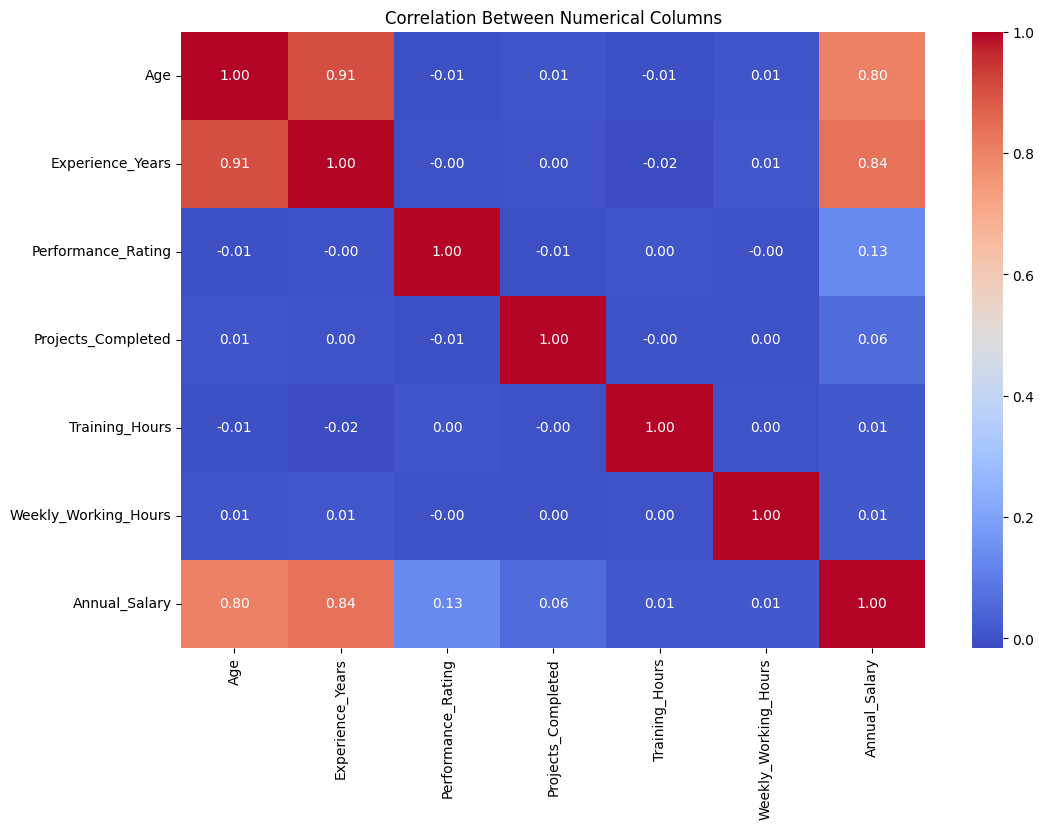

In [330]:
import seaborn as sns
import matplotlib.pyplot as plt


num_df = df.select_dtypes(include="number")
correlation = num_df.corr()
print(correlation)
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Columns")
plt.show()

In [340]:
df["Experience_Years"].corr(df["Annual_Salary"])

np.float64(0.8355621509237938)

In [342]:
df["City"].corr(df["Department"])

ValueError: could not convert string to float: 'Pune'

In [343]:
df.select_dtypes("int")

,Age,Experience_Years,Annual_Salary
0,24,1,85131
1,51,29,183609
2,47,22,125571
3,38,11,87186
4,38,16,114793
...,...,...,...
9995,39,18,143538
9996,60,39,177763
9997,35,11,154094
9998,43,20,157941


In [345]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


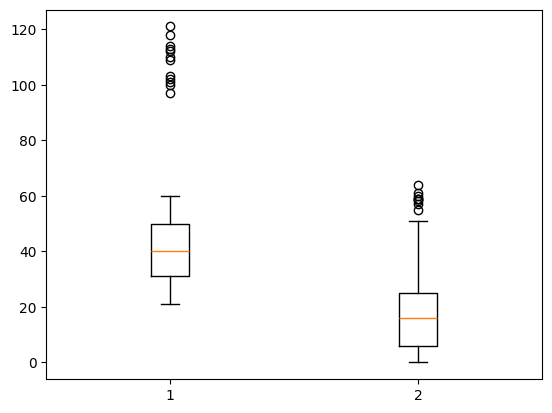

In [360]:
plt.boxplot(df[["Age","Experience_Years"]])
plt.show()

In [358]:
Q1 = df["Annual_Salary"].quantile(0.25)
Q3 = df["Annual_Salary"].quantile(0.75)

IQR  = Q3-Q1

low = Q1-1.5*(IQR)
high = Q3+1.5*(IQR)
# df.drop(df[df["Annual_Salary"]<low].index,inplace=True)
df[df["Annual_Salary"]<low]

,Age,Experience_Years,Education,Department,City,Performance_Rating,Projects_Completed,Training_Hours,Weekly_Working_Hours,Company_Size,Annual_Salary


In [364]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)

IQR = Q3-Q1

LOW = Q1-1.5*(IQR)
HIGH = Q3+1.5*(IQR)

df[(df["Age"]<LOW)|(df["Age"]>HIGH)]

df.drop(df[(df["Age"]<LOW)|(df["Age"]>HIGH)].index,inplace=True)

In [371]:
q1 = df["Experience_Years"].quantile(0.25)
q3 = df["Experience_Years"].quantile(0.75)

iqr = q3-q1

low = q1-1.5*(iqr)
high = q3+1.5*(iqr)

df[(df["Experience_Years"]<low)|(df["Experience_Years"]>high)]

df.drop(df[(df["Experience_Years"]<low)|(df["Experience_Years"]>high)].index,inplace=True)

In [374]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [375]:
model = LinearRegression()
model1 = DecisionTreeClassifier()
le = LabelEncoder()

In [377]:
x = df[["Age","Experience_Years"]]
y = df["Annual_Salary"]

In [378]:
from sklearn.model_selection import train_test_split

In [379]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=2222)

In [381]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [382]:
y_predict = model.predict(x_test)

In [383]:
y_predict

array([ 98708.25850054, 117990.89140131, 133656.58922553, ...,
       133656.58922553,  99599.22031272, 186890.4153834 ], shape=(1996,))

In [385]:
mae = mean_absolute_error(y_test,y_predict)
mae

14350.245301508578

In [386]:
mse = mean_squared_error(y_test,y_predict)
mse

322341335.5646548

In [387]:
rmse = root_mean_squared_error(y_test,y_predict)
rmse

17953.866869414367

In [388]:
r2 = r2_score(y_test,y_predict)

In [390]:
r2

0.7287613423807815

In [391]:
y_predict

array([ 98708.25850054, 117990.89140131, 133656.58922553, ...,
       133656.58922553,  99599.22031272, 186890.4153834 ], shape=(1996,))

In [392]:
y_test

6449    111687
9389    126853
6105    136875
963     105524
8132    164638
         ...  
5531    203815
7800    129440
1115    111138
3402    116987
1232    175410
Name: Annual_Salary, Length: 1996, dtype: Int64

In [396]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression 
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import  accuracy_score

In [400]:
df["Company_Size"] = le.fit_transform(df["Company_Size"])

In [403]:
df["Company_Size"].value_counts()

Company_Size
1    4570
0    3008
2    2400
Name: count, dtype: int64

In [404]:
df

,Age,Experience_Years,Education,Department,City,Performance_Rating,Projects_Completed,Training_Hours,Weekly_Working_Hours,Company_Size,Annual_Salary
0,24,1,Masters,Operations,Pune,1.7,5.000000,6.000000,38.1,1,85131
1,51,29,Masters,Marketing,Hyderabad,2.5,12.000000,3.000000,30.6,0,183609
2,47,22,Bachelor,Sales,Nagpur,2.4,3.000000,2.000000,31.0,0,125571
3,38,11,High school,Operations,Hyderabad,2.7,5.000000,2.000000,35.4,1,87186
4,38,16,Bachelor,Operations,Nashik,3.4,9.000000,2.991959,31.6,2,114793
...,...,...,...,...,...,...,...,...,...,...,...
9995,39,18,Masters,Finance,Delhi,2.4,7.000000,2.991959,45.9,2,143538
9996,60,39,Bachelor,Operations,Nashik,3.3,2.000000,3.000000,41.7,0,177763
9997,35,11,Masters,IT,Hyderabad,4.1,9.000000,2.000000,51.9,2,154094
9998,43,20,Masters,Sales,Delhi,2.8,6.000000,3.000000,39.8,1,157941


In [405]:
x_train

,Age,Experience_Years
4449,56,29
8452,49,20
7044,54,26
651,47,26
530,44,22
...,...,...
6841,55,32
7850,33,7
9372,21,0
145,55,31


In [406]:
df

,Age,Experience_Years,Education,Department,City,Performance_Rating,Projects_Completed,Training_Hours,Weekly_Working_Hours,Company_Size,Annual_Salary
0,24,1,Masters,Operations,Pune,1.7,5.000000,6.000000,38.1,1,85131
1,51,29,Masters,Marketing,Hyderabad,2.5,12.000000,3.000000,30.6,0,183609
2,47,22,Bachelor,Sales,Nagpur,2.4,3.000000,2.000000,31.0,0,125571
3,38,11,High school,Operations,Hyderabad,2.7,5.000000,2.000000,35.4,1,87186
4,38,16,Bachelor,Operations,Nashik,3.4,9.000000,2.991959,31.6,2,114793
...,...,...,...,...,...,...,...,...,...,...,...
9995,39,18,Masters,Finance,Delhi,2.4,7.000000,2.991959,45.9,2,143538
9996,60,39,Bachelor,Operations,Nashik,3.3,2.000000,3.000000,41.7,0,177763
9997,35,11,Masters,IT,Hyderabad,4.1,9.000000,2.000000,51.9,2,154094
9998,43,20,Masters,Sales,Delhi,2.8,6.000000,3.000000,39.8,1,157941


In [407]:
x = df[["Performance_Rating","Projects_Completed","Training_Hours","Weekly_Working_Hours","Company_Size","Age"]]
y = df["Annual_Salary"]

In [409]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=2222)

In [410]:
model = LinearRegression()

In [411]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [412]:
y_predict = model.predict(x_test)

In [413]:
y_predict

array([100371.56994934, 126120.6206477 , 119059.06384146, ...,
       125265.48767734, 106444.74435234, 174158.50876834], shape=(1996,))

In [414]:
y_test

6449    111687
9389    126853
6105    136875
963     105524
8132    164638
         ...  
5531    203815
7800    129440
1115    111138
3402    116987
1232    175410
Name: Annual_Salary, Length: 1996, dtype: Int64

In [416]:
r2 = r2_score(y_test,y_predict)

In [417]:
r2

0.7282853665715301